# Assignment 12: Spatial trait variation in California

## BIO597 Spatial Analysis of Biodiversity

Repeat [Lab12](../labs/Lab12-SpatialTraitVariation.ipynb) for California.
How do typical amphibian traits and local trait variation relate to latitude,
climate, and habitat across this larger, environmentally varied state?

Follow the lab's five analyses: community mean traits, functional dispersion,
a trait-shuffling null model, FDis–environment correlations, and a linked
community trait PCA map/biplot.
Use **30 km cells**, pool frogs and salamanders, and give each recorded species
equal weight. You may reuse and adapt code from the lab. Preparation helpers
are supplied so you can concentrate on the ecology.

Submit this notebook with figures, tables, short answers, and a **400–600 word
synthesis**. Include your name and cite the supplied data sources.

*Name:* Leonardo Villacis

## Inputs and environment

Run from `docs/assignments` using the Lab12 environment. The three California
files have the same layout and trait columns as the prepared Maine files:

| Input | Path from this notebook |
| --- | --- |
| Grid, climate, latitude, and habitat fractions | `../data/Lab12/CA_30KM_grid.geojson` |
| Occurrence counts by site and species | `../data/Lab12/CA_Amphib_site_by_species.csv` |
| Species with all five traits | `../data/Lab12/CA_traits.csv` |
| State boundary for map backgrounds | `../data/CA_ShapeFiles/California_State_Boundary.shp` |

The inputs are already prepared from `CA_amphibians.geojson`, `bioclim_CA`,
`CAHabitatMap`, and `AmphiTraits_Final.csv`. **Do not repeat occurrence cleaning,
name matching, gridding, or raster extraction.** Read the
[California preprocessing notes](../data/Lab12/CA_preprocessing.md), including
the species missing traits and the habitat crosswalk.

Records with coordinate uncertainty below 100 m were retained, including repeated
observations. The grid contains cells with more than two species. Counts are
numbers of records, not animal abundances. The California projection is
**EPSG:3310**, not Maine's UTM projection.

In [3]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

CRS = "EPSG:3310"
MIN_COVERAGE = 0.8
N_RANDOM = 1000
SEED = 12
DATA = Path("../data/Lab12")
OUTPUT = Path("outputs/Assignment12/SpatialTraitVariation")
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Load the prepared communities and traits

Load the three tables as `sites`, `community`, and `traits`. Use `site_id` as
the index for sites and communities, and `species` for traits, just as in the
lab. Load the boundary as `california` and project it to `CRS`.

Report the number of cells, recorded species, and species with complete traits.
Map recorded richness on the California background. Inspect `n_records` beside
richness and identify species absent from the complete trait table. The
preprocessing notes distinguish an unmatched name from a matched but incomplete
trait row.

In [4]:
# Load CA_30KM_grid.geojson, CA_Amphib_site_by_species.csv, and CA_traits.csv.
# Set the site and species indexes, as in Lab12.
# Load california and project it to CRS.
# Display table sizes, missing-trait species, and a richness map.

sites = gpd.read_file(DATA / "CA_30KM_grid.geojson")
sites = sites.set_index("site_id")
community = pd.read_csv(DATA / "CA_Amphib_site_by_species.csv", index_col="site_id")
traits = pd.read_csv(DATA / "CA_traits.csv", index_col="species")

print("Grid cells:", len(sites))
print("Recorded species:", len(community.columns))
print("Species with complete traits:", len(traits))
display(community.head())
display(traits)
display(sites.head())

Grid cells: 259
Recorded species: 70
Species with complete traits: 30


,Ambystoma californiense,Ambystoma gracile,Ambystoma macrodactylum,Ambystoma mavortium,Ambystoma tigrinum,Anaxyrus boreas,Anaxyrus californicus,Anaxyrus canorus,Anaxyrus cognatus,Anaxyrus microscaphus,...,Rana muscosa,Rana sierrae,Rhyacotriton variegatus,Spea hammondii,Spea intermontana,Taricha granulosa,Taricha rivularis,Taricha sierrae,Taricha torosa,Xenopus laevis
site_id,,,,,,,,,,,,,,,,,,,,,
-10_10,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
-10_11,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
-10_12,0,0,0,0,0,5,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
-10_14,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
-10_2,0,1,0,0,0,3,0,0,0,0,...,0,0,0,0,0,11,6,0,0,0


,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Ambystoma californiense,184.0,2.0,1340.0,75.0,413.0
Ambystoma gracile,219.0,2.0,270.0,70.0,30.0
Ambystoma macrodactylum,248.0,1.0,411.0,53.0,90.0
Anaxyrus boreas,125.0,3.0,16500.0,56.0,3239.0
Anaxyrus californicus,81.0,2.0,10368.0,51.0,2013.0
Anaxyrus canorus,69.0,3.0,5000.0,48.0,1500.0
Anaxyrus cognatus,114.0,2.0,45054.0,47.0,1342.0
Anaxyrus microscaphus,81.0,2.0,4500.0,53.0,3153.0
Aneides ferreus,133.0,2.0,18.0,75.0,6.0


,xc,yc,n_records,richness,latitude,bio_1,bio_2,bio_3,bio_4,bio_5,...,bio_19,habitat_agriculture,habitat_developed,habitat_open_water,habitat_other_natural,habitat_upland_forest,habitat_wetland,habitat_introduced,habitat_disturbed,geometry
site_id,,,,,,,,,,,,,,,,,,,,,
-10_10,-285000.0,315000.0,11,5,40.805612,10.370924,15.220775,50.022278,563.341797,29.490499,...,602.513916,0.000000,0.028938,0.004230,0.035765,0.912537,0.001166,0.004690,0.012674,"POLYGON ((-270000 300000, -270000 330000, -300..."
-10_11,-285000.0,345000.0,3,3,41.075714,9.215407,14.827040,50.508301,543.428833,27.603998,...,615.808228,0.000000,0.007646,0.000173,0.042195,0.932445,0.000987,0.006759,0.009795,"POLYGON ((-270000 330000, -270000 360000, -300..."
-10_12,-285000.0,375000.0,29,8,41.345892,10.155231,15.071324,50.350166,556.665222,28.863014,...,608.260864,0.000000,0.025189,0.004573,0.030108,0.899693,0.006871,0.013179,0.020387,"POLYGON ((-270000 360000, -270000 390000, -300..."
-10_14,-285000.0,435000.0,23,6,41.886505,9.646233,14.601047,49.404499,560.818115,28.115620,...,633.952393,0.000842,0.034330,0.004687,0.080455,0.844488,0.013303,0.008908,0.012987,"POLYGON ((-270000 420000, -270000 450000, -300..."
-10_2,-285000.0,75000.0,113,10,38.646715,12.921863,12.725392,57.320065,374.672791,25.699722,...,588.313721,0.000000,0.029211,0.004542,0.166304,0.766948,0.005328,0.016016,0.011651,"POLYGON ((-270000 60000, -270000 90000, -30000..."


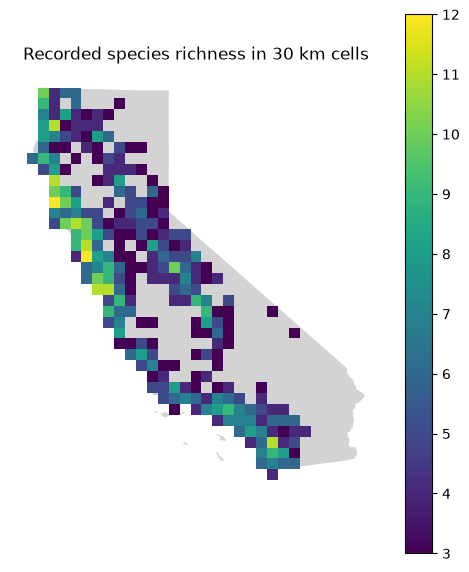

In [5]:
california = gpd.read_file("../data/CA_ShapeFiles/California_State_Boundary.shp")
california = california.to_crs(CRS).dissolve()

ax = california.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, column="richness", legend=True, figsize=(6, 7))
ax.set_title("Recorded species richness in 30 km cells")
ax.set_axis_off()
plt.show()

**Interpretation 1:** Where are recorded communities richest? Which sampling
gaps or differences in record totals might affect that pattern? Why must species
without complete traits still contribute to richness? Distinguish a species
absent from the trait table from a species absent from a cell.

Before looking at trait correlations, propose one directional hypothesis about
a trait and latitude, climate, or habitat, with a biological explanation.

*Your answer:* The highest species richness occurs in the northwest portion of the state. There are sampling gaps in the valley and southeast portion of the state. This may affect spatial analsyses and species richness is a function of the number of species while traits data is rather independent of the number of species, as this is a different metric for diversity. I hypothesize that trait diversity will be higher with heterogenious areas such as mountain ranges which generate ecotones. Ecotones tend to mix an array of climates which tribute to higher diversity. 

## 2. Put species in a shared trait space

Use all five supplied traits. Log-transform them, standardize the columns,
and fit a two-component **species PCA**. Save `trait_space`, `trait_pca`,
`species_scores`, and `loadings`, following the lab. Plot species in PCA space,
label them, and display the loadings and variance explained.

Traits describe typical species values, not measurements of animals at each
observation. Frogs and salamanders remain together throughout this assignment.

In [6]:
TRAIT_COLUMNS = list(traits.columns)
TRAIT_LABELS = {
    "MaxBody": "Maximum adult length (mm)",
    "MinAgeMat": "Minimum maturity age (years)",
    "MaxClutch": "Maximum clutch size",
    "MinSizeMat": "Minimum size at maturity (mm)",
    "MinClutch": "Minimum clutch size",
}
trait_lookup = traits

,PC1,PC2
MaxBody,-0.364826,0.558965
MinAgeMat,-0.436368,0.017596
MaxClutch,0.539965,0.382823
MinSizeMat,-0.330057,0.618403
MinClutch,0.525344,0.397836


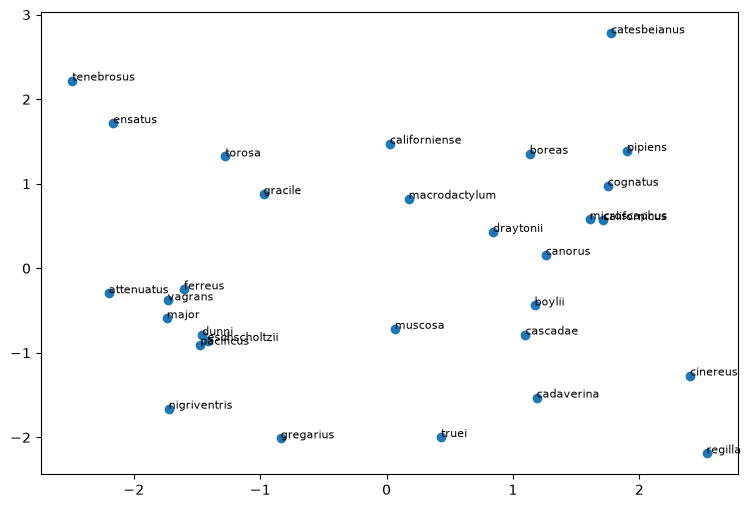

In [61]:
# Log10-transform and standardize traits, then create trait_space.
# Fit trait_pca and make species_scores and loadings.
# Plot the species and report the variance explained by PC1 and PC2.

# Log and standardize the data
logged = np.log10(traits)
scaler = StandardScaler()
standardized = scaler.fit_transform(logged)
trait_space = pd.DataFrame(standardized, index=traits.index, columns=TRAIT_COLUMNS)

# Perform PCA
trait_pca = PCA(n_components=2)
scores = trait_pca.fit_transform(standardized)
species_scores = pd.DataFrame(scores, index=traits.index, columns=["PC1", "PC2"])

# Scatterplot of PCs
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(species_scores["PC1"], species_scores["PC2"])
for name, point in species_scores.iterrows():
    epithet = name.split()[1]
    ax.text(point["PC1"], point["PC2"], epithet, fontsize=8)

loadings = pd.DataFrame(trait_pca.components_.T, index=TRAIT_COLUMNS, columns=["PC1", "PC2"])
display(loadings)

loadings.to_csv(OUTPUT / "life strategy pca.csv")

In [8]:
display(trait_lookup.sort_values('MaxBody').head(3))
display(trait_lookup.sort_values('MaxBody').tail(3))

,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Ascaphus truei,50.0,2.0,96.0,34.0,28.0
Pseudacris regilla,50.0,1.0,807.0,19.0,265.0
Pseudacris cadaverina,51.0,2.0,265.0,32.0,265.0


,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Ambystoma macrodactylum,248.0,1.0,411.0,53.0,90.0
Dicamptodon ensatus,300.0,5.0,200.0,88.9,70.0
Dicamptodon tenebrosus,340.0,5.0,146.0,115.0,83.0


**Interpretation 2:** What biological combinations distinguish the two axes?
Choose two nearby species and two contrasting species, referring to their
original trait values. Why log-transform and standardize? Why should functional
dispersion use all five traits even when the figure displays two PCs?

*Your answer:* large clutch with small body vs small clutch with large body drives the first axis. Axis 2 is positive on all variables but is mostly driven by minSizeMaturity. Dicamptodon tenebrosus and D. ensatus are both in the extreme of largest body size with relatively small clutch size, while these contrast with Pseudacris regilla which is on the other extreme of the ordination plot with small body size and large clutches. The transformation and standardizations are necessary to compare the varience and have the same range of deviation. Functional dispersion requiers all five traits because they are all important descriptors.

## 3. Map typical community traits

Use the supplied helper from Lab12. Each species present receives one vote;
repeated records do not increase its weight. The helper returns a geometric
mean and the proportion of recorded species with trait information. Means below
80% coverage remain missing.

Build `trait_maps` for all five traits. Map maximum body length, maturity age,
and maximum clutch size, using `california` as the background. Inspect coverage
as well as the trait means; do not fill missing means with zero.

In [9]:
def summarize_trait(sites, community, column):
    result = sites.copy()
    means = []
    coverages = []
    for site_id, row in community.iterrows():
        # Get only the species that occur in this community
        names = row[row > 0].index
        # reindex the trait lookup table to only have those species present
        species_traits = trait_lookup.reindex(names)
        values = species_traits[column]
        values = values.dropna()
        # calculate the fraction of species that have trait info
        coverage = len(values) / len(names)
        coverages.append(coverage)
        if coverage >= MIN_COVERAGE:
            log_values = np.log10(values)
            means.append(10 ** log_values.mean())
        else:
            means.append(np.nan)
    result["trait_mean"] = means
    result["trait_coverage"] = coverages
    return result

Maximum length (mm): 127 of 259 cells with data
Minimum age at maturity: 127 of 259 cells with data
Maximum clutch size: 127 of 259 cells with data


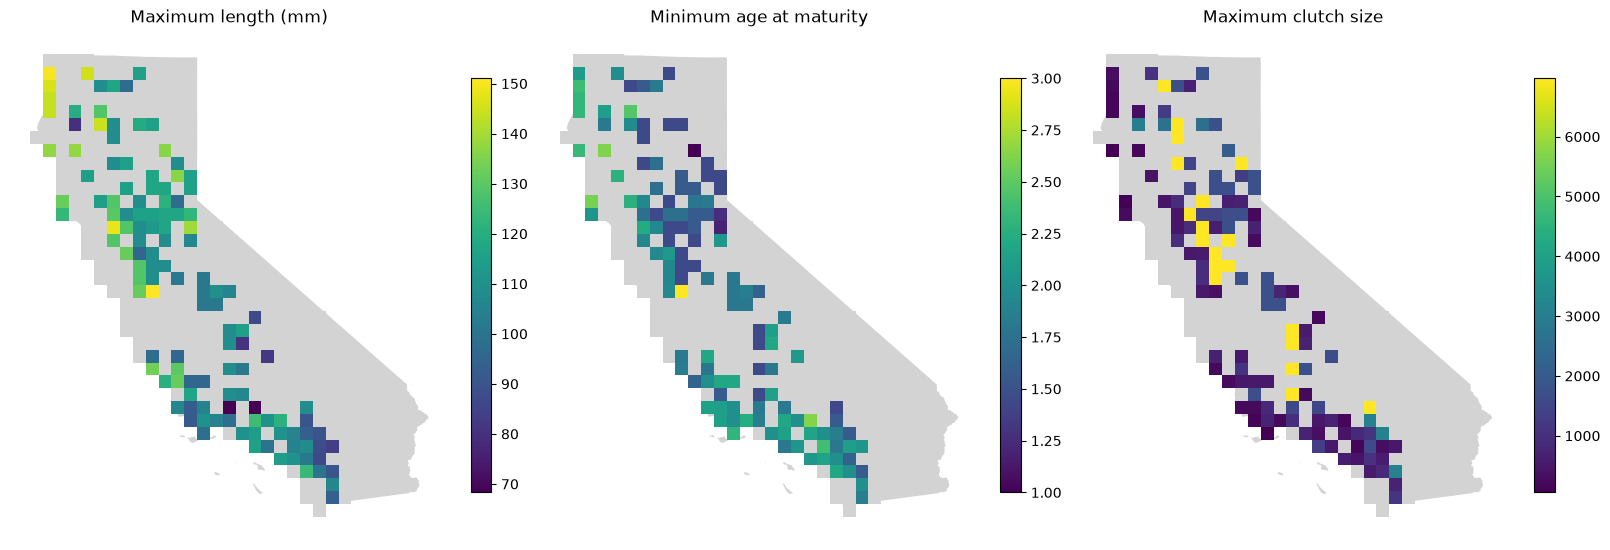

In [10]:
# Build trait_maps by calling summarize_trait for each trait.
# Map MaxBody, MinAgeMat, and MaxClutch with appropriate labels.
# Examine how many cells retain valid trait means and where coverage is low.
trait_maps = {}
for column in TRAIT_COLUMNS:
    trait_maps[column] = summarize_trait(sites, community, column)

titles = {
    "MaxBody": "Maximum length (mm)",
    "MinAgeMat": "Minimum age at maturity",
    "MaxClutch": "Maximum clutch size",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

for ax, (column, title) in zip(axes, titles.items()):
    california.plot(ax=ax, color="lightgray")
    sites.plot(ax=ax, color="lightgray")

    trait_map = trait_maps[column]
    trait_map.plot(
        ax=ax,
        column="trait_mean",
        legend=True,
        legend_kwds={"shrink": 0.7},
    )

    n_valid = trait_map["trait_mean"].notna().sum()
    ax.set_title(f"{title}")
    ax.set_axis_off()
    print(f"{title}: {n_valid} of {len(sites)} cells with data")

plt.show()


**Interpretation 3:** Where do typical community traits differ? Could missing
traits or differences in sampling help explain those patterns? Describe what
"typical maximum body length" means without treating it as mean animal size.
Which areas are excluded by the coverage requirement?

*Your answer:* Trait characteristics tend to be different in the central valley, compared to the surroundings. As this area is heavily agricultural, it is difficult to untangle this effect from that of samling effort or genuine climatic gradients that drive these trait characteristics. Maximum body length is a proxy for heat resistance, as larger animals do best in cooler climates, and visa versa. The southeastern area is excluded due to coverage requirements.

### Compare typical traits with the predictors

The prepared grid includes midpoint latitude, all 19 BIO variables, and habitat
area fractions. These are **cell means and area fractions**, rather than SDs or
the habitat proportions of occurrence records. Habitat fractions sum to one over
classified pixels in the California portion of each cell, including mapped water.

California's original map legend differs from Maine's. The first six broad groups
are analogous to the lab; `habitat_introduced` and `habitat_disturbed` retain two
additional mapped categories. "Other natural" includes shrubland, grassland,
desert, alpine and rock vegetation. Exact habitat comparisons between states
require care because the source maps differ.

Calculate descriptive **Spearman correlations** between typical maximum length
and every predictor. Make six example scatterplots using `PLOT_PREDICTORS`.
You may substitute other predictors if you explain the choice.

In [11]:
CLIMATE_COLUMNS = {
    "bio_1": "Annual mean temperature (°C)",
    "bio_2": "Mean diurnal temperature range (°C)",
    "bio_3": "Isothermality (%)",
    "bio_4": "Temperature seasonality (SD × 100)",
    "bio_5": "Maximum temperature, warmest month (°C)",
    "bio_6": "Minimum temperature, coldest month (°C)",
    "bio_7": "Annual temperature range (°C)",
    "bio_8": "Mean temperature, wettest quarter (°C)",
    "bio_9": "Mean temperature, driest quarter (°C)",
    "bio_10": "Mean temperature, warmest quarter (°C)",
    "bio_11": "Mean temperature, coldest quarter (°C)",
    "bio_12": "Annual precipitation (mm)",
    "bio_13": "Precipitation, wettest month (mm)",
    "bio_14": "Precipitation, driest month (mm)",
    "bio_15": "Precipitation seasonality (CV)",
    "bio_16": "Precipitation, wettest quarter (mm)",
    "bio_17": "Precipitation, driest quarter (mm)",
    "bio_18": "Precipitation, warmest quarter (mm)",
    "bio_19": "Precipitation, coldest quarter (mm)",
}

HABITAT_COLUMNS = {
    "habitat_agriculture": "Agriculture fraction",
    "habitat_developed": "Developed fraction",
    "habitat_open_water": "Open water fraction",
    "habitat_other_natural": "Other natural habitat fraction",
    "habitat_upland_forest": "Upland forest fraction",
    "habitat_wetland": "Wetland/aquatic vegetation fraction",
    "habitat_introduced": "Introduced vegetation fraction",
    "habitat_disturbed": "Recently disturbed fraction",
}
PREDICTORS = {"latitude": "Midpoint latitude (°N)"}
PREDICTORS.update(CLIMATE_COLUMNS)
PREDICTORS.update(HABITAT_COLUMNS)


PLOT_PREDICTORS = ["latitude", "bio_1", "bio_6", "bio_10",
                   "habitat_upland_forest", "habitat_developed"]

{'latitude': np.float64(0.5),
 'bio_1': np.float64(-0.2),
 'bio_2': np.float64(-0.31),
 'bio_3': np.float64(0.09),
 'bio_4': np.float64(-0.18),
 'bio_5': np.float64(-0.3),
 'bio_6': np.float64(-0.01),
 'bio_7': np.float64(-0.25),
 'bio_8': np.float64(-0.13),
 'bio_9': np.float64(-0.23),
 'bio_10': np.float64(-0.29),
 'bio_11': np.float64(-0.11),
 'bio_12': np.float64(0.49),
 'bio_13': np.float64(0.52),
 'bio_14': np.float64(0.24),
 'bio_15': np.float64(-0.01),
 'bio_16': np.float64(0.5),
 'bio_17': np.float64(0.27),
 'bio_18': np.float64(0.25),
 'bio_19': np.float64(0.51),
 'habitat_agriculture': np.float64(-0.07),
 'habitat_developed': np.float64(-0.05),
 'habitat_open_water': np.float64(0.21),
 'habitat_other_natural': np.float64(-0.38),
 'habitat_upland_forest': np.float64(0.32),
 'habitat_wetland': np.float64(0.15),
 'habitat_introduced': np.float64(0.14),
 'habitat_disturbed': np.float64(0.23)}

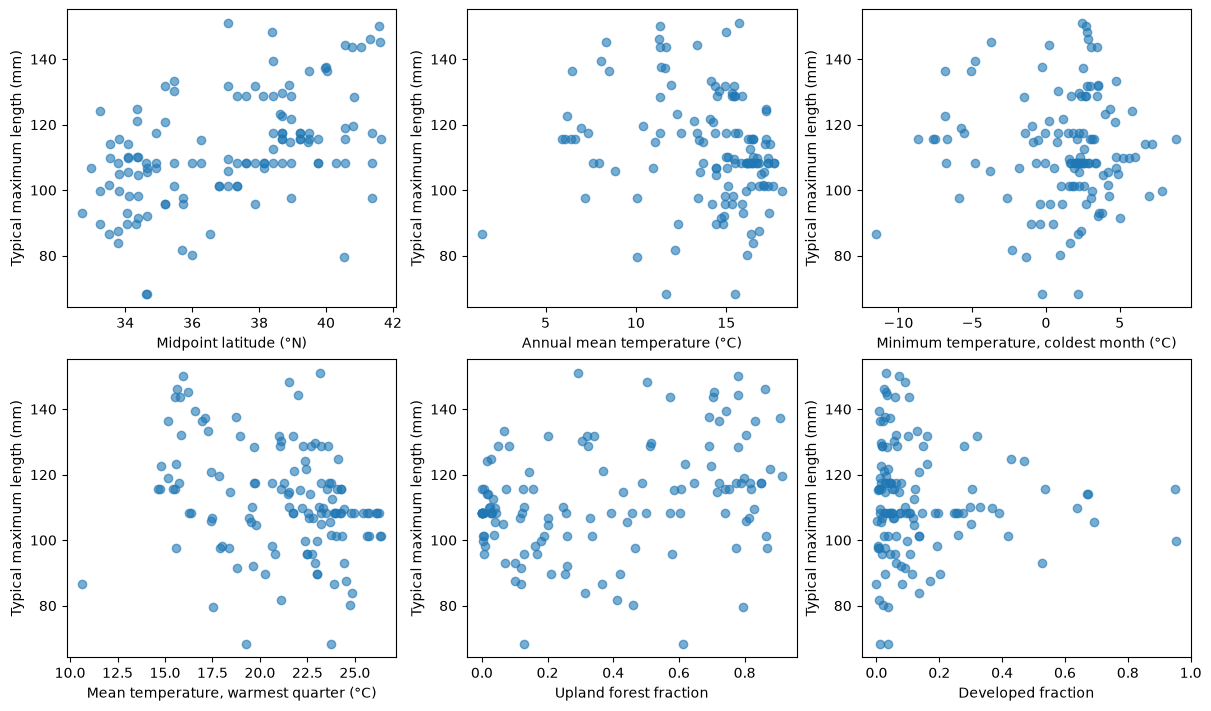

In [12]:
# Compare trait_maps["MaxBody"] with all predictors using Spearman correlation.
# Plot six example relationships with labels from PREDICTORS.


table = trait_maps["MaxBody"]
corrs = {}
for predictor in PREDICTORS:
    data = table.dropna(subset=["trait_mean", predictor])
    rho = data[predictor].corr(data["trait_mean"], method="pearson")
    corrs[predictor] = round(rho, 2)
display(corrs)

# Show examples from latitude, climate, and habitat.
PLOT_PREDICTORS = ["latitude", "bio_1", "bio_6", "bio_10",
                   "habitat_upland_forest", "habitat_developed"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, predictor in zip(axes.flat, PLOT_PREDICTORS):
    data = table.dropna(subset=["trait_mean", predictor])
    ax.scatter(data[predictor], data["trait_mean"], alpha=0.6)
    ax.set(xlabel=PREDICTORS[predictor], ylabel="Typical maximum length (mm)")
plt.show()

**Interpretation 4:** Does the pattern support your initial hypothesis?
Compare a geographic, a climatic, and a habitat relationship. Why would a strong
correlation alone fail to identify an independent cause? Explain how habitat
fractions constrain one another.

*Your answer:* This partially supports my hypothesis since the developed fraction harbors very low range in maximum length while the higher upland fraction tends to generate a largre spread of this trait. There seems to be a weak increase in body size as latitude increases. Body size also decreases as mean temp of warmest quater incresaes. There is a strong size selection as the developed fraction increases. Habitat constrain one another because they do not co occure and limit the land available for other fractions.

## 4. Richness versus functional dispersion

The community matrix includes species without complete traits. **Do not use
`trait_space.loc[names]` on the full species list.** The supplied code below
selects species with complete traits and cells with at least three of those
species and at least 80% coverage. Use `functional_sites` and
`functional_presence` for all FDis calculations and the null model.

Use the lab's dispersion function to calculate FDis for each retained cell,
using all five standardized log traits. Map `trait_richness` and FDis, then plot
their relationship. Also inspect how trait richness differs from total recorded
richness. The cell mean trait maps and FDis summarize different properties.

In [13]:
# Select complete-trait species and keep matching grid cells.
known_presence = community[trait_space.index] > 0
functional_sites = sites.copy()
functional_sites["trait_richness"] = known_presence.sum(axis=1)
functional_sites["trait_coverage"] = functional_sites["trait_richness"] / sites["richness"]
functional_sites = functional_sites[functional_sites["trait_coverage"] >= MIN_COVERAGE]
functional_sites = functional_sites[functional_sites["trait_richness"] >= 3].copy()
functional_presence = known_presence.loc[functional_sites.index]
print("Cells retained for functional analyses:", len(functional_sites))


def dispersion(values):
    centroid = values.mean(axis=0)
    squared_differences = (values - centroid) ** 2
    distances = np.sqrt(squared_differences.sum(axis=1))
    return distances.mean()

for site_id, present in functional_presence.iterrows():
    present_species = present.index[present]
    trait_values = trait_space.loc[present_species]
    functional_sites.loc[site_id, "functional_dispersion"] = dispersion(trait_values)

display(functional_sites[["trait_richness", "trait_coverage", "functional_dispersion"]])

Cells retained for functional analyses: 127


,trait_richness,trait_coverage,functional_dispersion
site_id,,,
-10_10,4,0.800000,2.482117
-10_7,3,1.000000,1.901075
-10_9,3,1.000000,1.612419
-11_2,5,1.000000,2.223451
-11_3,6,0.857143,2.441239
...,...,...,...
8_-18,6,1.000000,2.458576
9_-15,4,1.000000,2.304045
9_-16,5,0.833333,2.177951


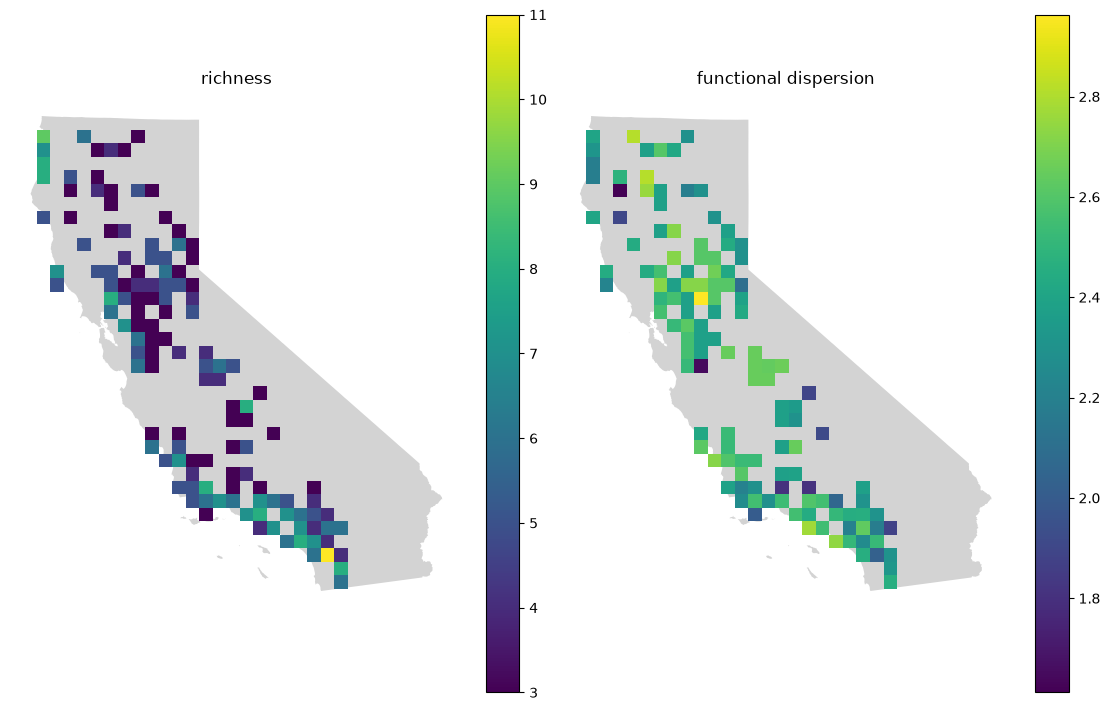

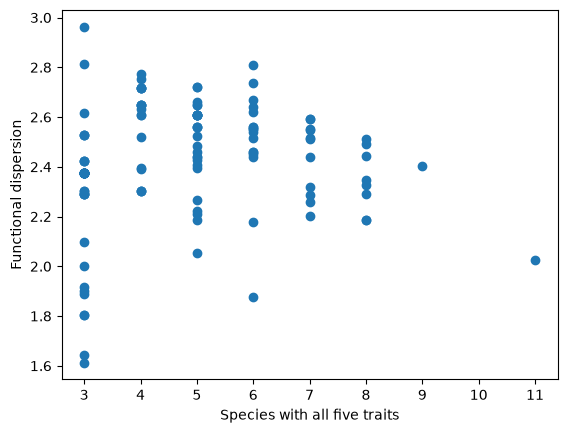

In [14]:
# For each row of functional_presence, select the species present.
# Look up their standardized traits and calculate dispersion.
# Store the results in functional_sites["functional_dispersion"].
# Map trait_richness and functional_dispersion, and plot their relationship.


fig, axes = plt.subplots(1, 2, figsize=(11, 7), layout="constrained")
for ax, column in zip(axes, ["richness", "functional_dispersion"]):
    california.plot(ax=ax, color="lightgray", figsize=(6, 7))
    functional_sites.plot(ax=ax, color="lightgray")
    functional_sites.plot(ax=ax, column=column, legend=True)
    ax.set_title(column.replace("_", " "))
    ax.set_axis_off()
plt.show()

plt.scatter(functional_sites["richness"], functional_sites["functional_dispersion"])
plt.xlabel("Species with all five traits")
plt.ylabel("Functional dispersion")
plt.show()


### Hold richness fixed

Among retained cells with **four trait-covered species**, select the lowest and
highest FDis. Draw their species on the species PCA with the regional species
pool in gray and the local centroid marked. Print both species lists and FDis
values. Use `trait_richness`, not total richness, to hold the number of analyzed
species fixed.

Cell 10_-18: Species: Anaxyrus boreas, Lithobates catesbeianus, Pseudacris cadaverina, Pseudacris regilla
Cell 4_-16: Species: Anaxyrus boreas, Batrachoseps nigriventris, Lithobates catesbeianus, Pseudacris regilla


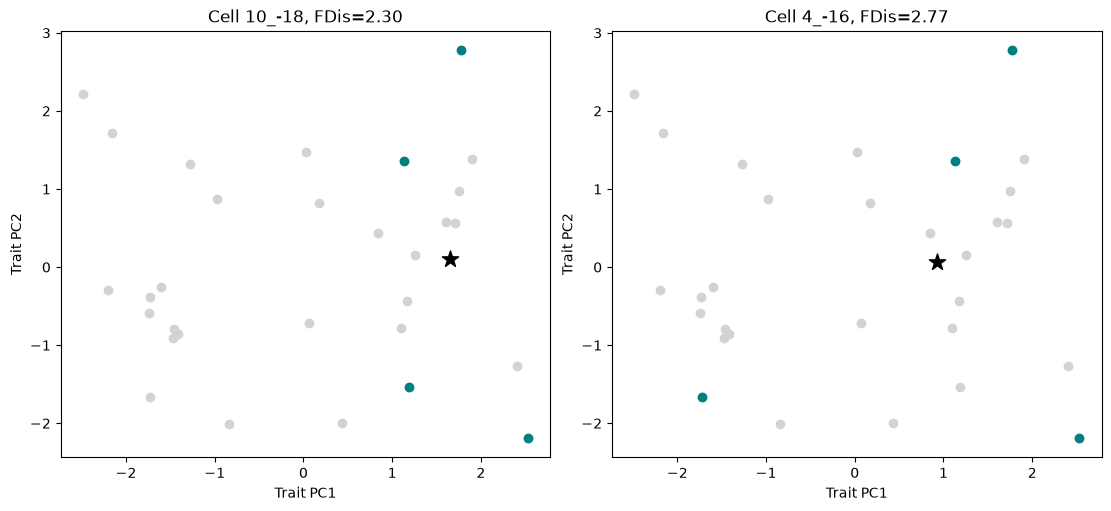

In [24]:
# Find low and high FDis cells with trait_richness == 4.
# Plot each local species set and centroid on the species PCA.
# Print the cell IDs, species lists, and FDis values.

candidates = functional_sites[functional_sites["richness"] == 4]
lowest = candidates["functional_dispersion"].idxmin()
highest = candidates["functional_dispersion"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, site_id in zip(axes, [lowest, highest]):
    present = community.loc[site_id]
    names = present[present > 0].index
    selected = species_scores.loc[names]
    ax.scatter(species_scores["PC1"], species_scores["PC2"], color="lightgray")
    ax.scatter(selected["PC1"], selected["PC2"], color="teal")
    ax.scatter(selected["PC1"].mean(), selected["PC2"].mean(), marker="*", color="black", s=150)
    fdis = functional_sites.loc[site_id, "functional_dispersion"]
    ax.set(title=f"Cell {site_id}, FDis={fdis:.2f}", xlabel="Trait PC1", ylabel="Trait PC2")
    print(f"Cell {site_id}: Species: {', '.join(names)}")
plt.show()

**Interpretation 5:** Which species and traits create the contrast? Can two
equally rich communities have different functional diversity? Explain why a PCA
picture can miss differences measured by the full five-dimensional FDis.
Would your conclusions change if the excluded species had very unusual traits?

*Your answer:* Pseudacris cadaverina and Batrachoseps nigriventris are the species that are unique to each cell respectively. Two equally rich communities can have very different functional diversity. The PCA captures the varience among traits in two dimensions through correlation, but the FDi is a measure of distance which is different from correlation. In PCA space I don't think that would change too much. 

## 5. Compare dispersion with a null model

Use **1,000 shuffles** and seed 12, matching the current lab. Each shuffle
reassigns whole five-trait profiles among the complete-trait California species
while keeping each cell's species list fixed. The helper is provided below.

Call it with `functional_presence`, not raw record counts or a different set of
cells. Save the result as `null_draws`. Copy `functional_sites` to `null_sites`,
calculate the null mean and sample SD for each cell, and calculate:

`ses_fdis = (observed FDis - null mean) / null SD`

Leave SES missing when the null SD is zero or nearly zero, as in the lab.
Map SES with a common scale of −3 to +3. Plot a null histogram for one cell and
mark its observed FDis. These effect sizes are not, by themselves, p-values.

In [30]:
def null_dispersion(presence, trait_space, n_random):
    # Match the species order, then turn occurrence counts into presence/absence.
    presence = presence[trait_space.index]
    presence = presence > 0
    values = trait_space.to_numpy()
    rng = np.random.default_rng(SEED)

    # Store one dispersion value per randomization and grid cell.
    simulated = np.zeros((n_random, len(presence)))
    for draw in range(n_random):
        # Reassign whole trait profiles among species; keep all five traits together.
        shuffled = rng.permutation(values)
        for site_number, present in enumerate(presence.to_numpy()):
            # Keep the cell's species list fixed and calculate its shuffled dispersion.
            simulated[draw, site_number] = dispersion(shuffled[present])
    return simulated

N_RANDOM = 1000
null_sites = functional_sites.copy()
null_draws = null_dispersion(functional_presence.loc[null_sites.index], trait_space, N_RANDOM)

# Summarize the dispersion expected by chance for each cell.
null_sites["null_mean"] = null_draws.mean(axis=0)
null_sites["null_sd"] = null_draws.std(axis=0, ddof=1)

# Compare observed dispersion with the null mean, in units of null SD.
# Leave the effect size missing if the randomizations have no variation.
null_sites.loc[null_sites["null_sd"] < 1e-10, "null_sd"] = np.nan
difference = null_sites["functional_dispersion"] - null_sites["null_mean"]
null_sites["ses_fdis"] = difference / null_sites["null_sd"]

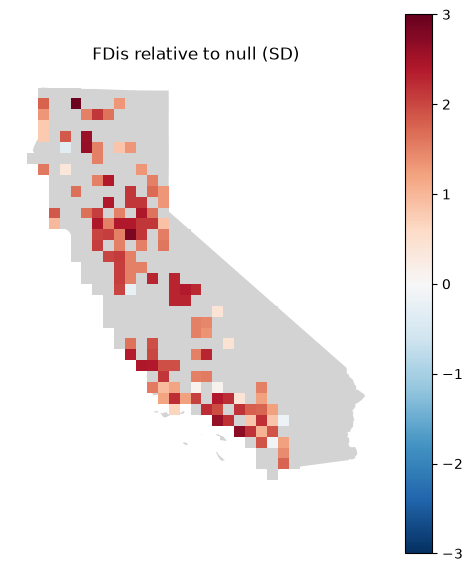

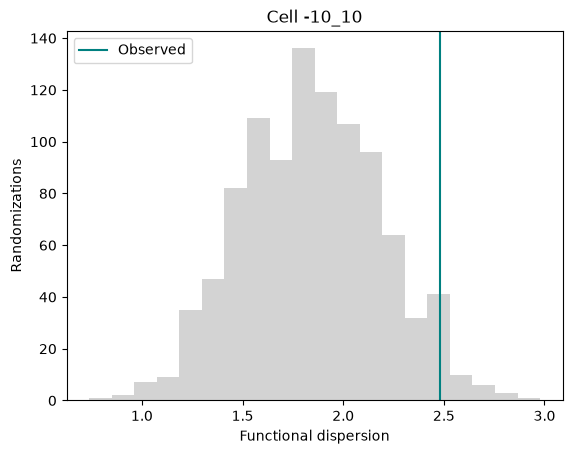

In [31]:
ax = california.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, color="lightgray", figsize=(6, 7))
null_sites.plot(ax=ax, column="ses_fdis", cmap="RdBu_r", vmin=-3, vmax=3, legend=True)
ax.set_title("FDis relative to null (SD)")
ax.set_axis_off()
plt.show()

# Look at the randomization distribution for one cell.
examples = null_sites.dropna(subset=["ses_fdis"])
site_id = examples.index[0]
position = null_sites.index.get_loc(site_id)
plt.hist(null_draws[:, position], bins=20, color="lightgray")
observed = null_sites.loc[site_id, "functional_dispersion"]
plt.axvline(observed, color="teal", label="Observed")
plt.title(f"Cell {site_id}")
plt.xlabel("Functional dispersion")
plt.ylabel("Randomizations")
plt.legend()
plt.show()

**Interpretation 6:** Which communities are more clustered or spread out
than expected from this regional pool? What does the null model keep fixed?
Why shuffle all traits together? Explain why clustering does not establish
environmental filtering and why the choice of species pool matters.

*Your answer:* Most communities are more spread out than expected and are spread throughout California. Only a few cells have slightly more clustered than expected. The null model keeps standard deviation at zero. Shuffeling all traits together simulates a way to test against the results happening by chance or not. Clustering does not establish filtering because it may also have to do with a sampling bias. 

## 6. Evaluate correlations between FDis and environmental predictors

Repeat **Step 4 of Lab12** using the California communities. Calculate
**Pearson correlations** between observed `functional_dispersion` and every
predictor. Use `null_sites`, which already contains the observed FDis and
predictors for the retained cells. Omit missing values for each comparison.

Display the correlations and make the same six scatterplots as the lab using
`PLOT_PREDICTORS`: latitude, annual mean temperature, minimum temperature of
the coldest month, mean temperature of the warmest quarter, upland forest
fraction, and developed fraction. Label the vertical axis **Functional dispersion**.

These plots describe how much traits vary within communities. Use observed
FDis here; the SES map in Section 5 asks whether that spread differs from the
regional null expectation. The correlations are descriptive, and nearby cells
share species and environmental conditions.

Pearson correlations


{'latitude': np.float64(0.1),
 'bio_1': np.float64(0.27),
 'bio_2': np.float64(0.01),
 'bio_3': np.float64(-0.02),
 'bio_4': np.float64(0.01),
 'bio_5': np.float64(0.22),
 'bio_6': np.float64(0.22),
 'bio_7': np.float64(0.01),
 'bio_8': np.float64(0.23),
 'bio_9': np.float64(0.3),
 'bio_10': np.float64(0.24),
 'bio_11': np.float64(0.21),
 'bio_12': np.float64(-0.05),
 'bio_13': np.float64(-0.01),
 'bio_14': np.float64(-0.17),
 'bio_15': np.float64(0.2),
 'bio_16': np.float64(-0.03),
 'bio_17': np.float64(-0.19),
 'bio_18': np.float64(-0.26),
 'bio_19': np.float64(-0.03),
 'habitat_agriculture': np.float64(0.14),
 'habitat_developed': np.float64(0.24),
 'habitat_open_water': np.float64(-0.01),
 'habitat_other_natural': np.float64(-0.2),
 'habitat_upland_forest': np.float64(-0.07),
 'habitat_wetland': np.float64(0.1),
 'habitat_introduced': np.float64(-0.18),
 'habitat_disturbed': np.float64(-0.12)}

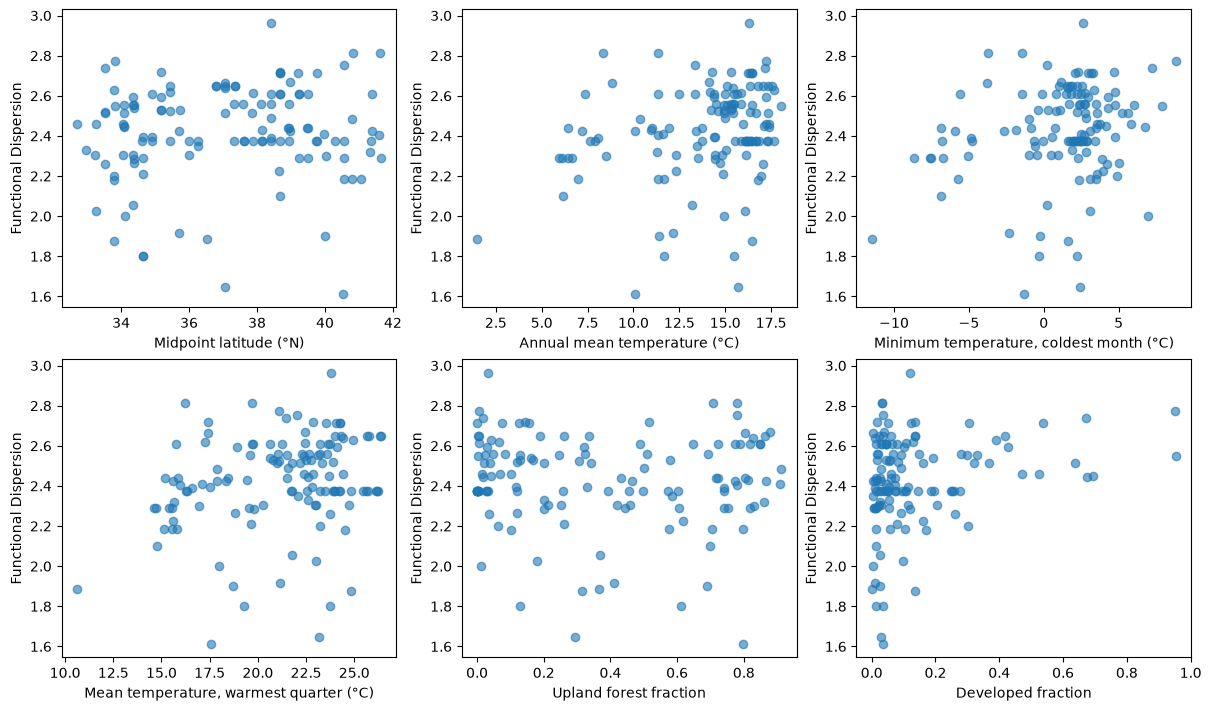

In [32]:
# Calculate Pearson correlations between functional_dispersion and all PREDICTORS.
# Drop missing values for each comparison and display the correlations.
# Make six FDis scatterplots using PLOT_PREDICTORS, as in Lab12 Step 4.

Fdis_corrs = {}
for predictor in PREDICTORS:
    data = null_sites.dropna(subset=["functional_dispersion", predictor])
    r = data[predictor].corr(data["functional_dispersion"], method="pearson")
    Fdis_corrs[predictor] = round(r, 2)
print("Pearson correlations")
display(Fdis_corrs)

fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, predictor in zip(axes.flat, PLOT_PREDICTORS):
    data = null_sites.dropna(subset=["functional_dispersion", predictor])
    ax.scatter(data[predictor], data["functional_dispersion"], alpha=0.6)
    ax.set(xlabel=PREDICTORS[predictor], ylabel="Functional Dispersion")
plt.show()

In [57]:
display(data.head(1).index)
data.iloc[0,:]

Index(['-10_10'], dtype='str', name='site_id')

xc                                                               -285000.0
yc                                                                315000.0
n_records                                                               11
richness                                                                 5
latitude                                                         40.805612
bio_1                                                            10.370924
bio_2                                                            15.220775
bio_3                                                            50.022278
bio_4                                                           563.341797
bio_5                                                            29.490499
bio_6                                                            -0.956222
bio_7                                                            30.446724
bio_8                                                              4.78012
bio_9                    

**Interpretation 7:** Which predictors have the strongest associations with
trait dispersion? Do these resemble the relationships with typical maximum
length? Distinguish a community's mean traits, its observed trait spread, and
its departure from the regional null expectation. Propose one biological
explanation for the strongest pattern and one alternative involving sampling
or species availability.

*Your answer:* Mean annual temperature has the highest correlation (0.27) with FDi. They do not actually have the same relationship with maximum length, whose best predictor had to do with precipitation and seasonality. Site 10-10 has low temperature (bio1=10 °C) and high precipition (bio12: 1257 mm) which makes sense as it is at the very north of the state. Fdi is 2.5 which is higher than the null model. This environment can generate many microclimates, particularly related to the topography which generate rain shadows and shelters. This may generate the relatively high dispersion. The species richness is 5 so there may be a limited estimate for FDi and may be missig other members of the community that are difficult to detect. 

## 7. Put community trait combinations on the map

Repeat the lab's final synthesis using the retained functional cells:

1. Assemble their five geometric mean traits from `trait_maps`, take log10,
   standardize, and fit a new **community PCA**. One row is now a grid cell.
2. Rank every predictor by its average squared Pearson correlation with the
   five log community mean traits. Select the leading climate variable and
   leading habitat fraction. This ranking is descriptive, not a significance test.
3. Color cells using their first two PC scores, as in the lab. Use identical
   colors for each cell on the California map and in the PCA scatterplot.
4. Add arrows for **latitude, the leading climate variable, and the leading
   habitat fraction**, using their correlations with the displayed PC axes.

Keep names such as `community_traits`, `community_pca`, `community_scores`,
`community_loadings`, `predictor_ranking`, and `map_sites` from the lab. Use
`sites` for the gray background and only the retained cells for the colored map.
Report the variance explained and show the trait loadings and predictor ranking.

In [58]:
# Build community_traits for functional_sites.index from the five trait_maps.
# Log10-transform, standardize, and calculate community_scores and loadings.
# Rank PREDICTORS using all five log community mean traits.
# Select latitude, the leading climate variable, and the leading habitat fraction.

from sklearn.preprocessing import MinMaxScaler

# Reuse the community mean traits already calculated in Step 1.
community_traits = pd.DataFrame(index=sites.index)
for trait in TRAIT_COLUMNS:
    community_traits[trait] = np.log10(trait_maps[trait]["trait_mean"])
community_traits = community_traits.dropna()

# Give each trait equal weight, then summarize differences among cells.
scaler = StandardScaler()
scaled_traits = scaler.fit_transform(community_traits)
community_pca = PCA(n_components=2)
scores = community_pca.fit_transform(scaled_traits)
community_scores = pd.DataFrame(scores, index=community_traits.index, columns=["PC1", "PC2"])
community_loadings = pd.DataFrame(community_pca.components_.T,
                                 index=TRAIT_COLUMNS, columns=["PC1", "PC2"])
display(community_loadings)

# Compare latitude, climate, and habitat using all five community mean traits.
predictor_strength = {}
for predictor in PREDICTORS:
    squared_correlations = []
    for trait in TRAIT_COLUMNS:
        r = sites[predictor].corr(community_traits[trait])
        squared_correlations.append(r ** 2)
    predictor_strength[predictor] = np.mean(squared_correlations)

predictor_ranking = pd.Series(predictor_strength, name="mean_r_squared")
predictor_ranking = predictor_ranking.sort_values(ascending=False)
best_climate = predictor_ranking.loc[list(CLIMATE_COLUMNS)].idxmax()
best_habitat = predictor_ranking.loc[list(HABITAT_COLUMNS)].idxmax()
FOCUS = ["latitude", best_climate, best_habitat]
display(predictor_ranking.head())

# Use the same PCA-based colors in the map and the scatterplot.
color_scores = MinMaxScaler().fit_transform(community_scores)
community_colors = np.zeros((len(community_scores), 3))
community_colors[:, :2] = color_scores
community_colors[:, 2] = 0.5
map_sites = sites.loc[community_scores.index].copy()
map_sites[["PC1", "PC2"]] = community_scores

,PC1,PC2
MaxBody,-0.237402,0.658078
MinAgeMat,-0.506141,-0.129573
MaxClutch,0.579711,0.181433
MinSizeMat,-0.156041,0.699870
MinClutch,0.571881,0.165553


bio_7     0.188495
bio_4     0.183454
bio_3     0.147214
bio_5     0.143421
bio_13    0.115724
Name: mean_r_squared, dtype: float64

ValueError: RGBA values should be within 0-1 range

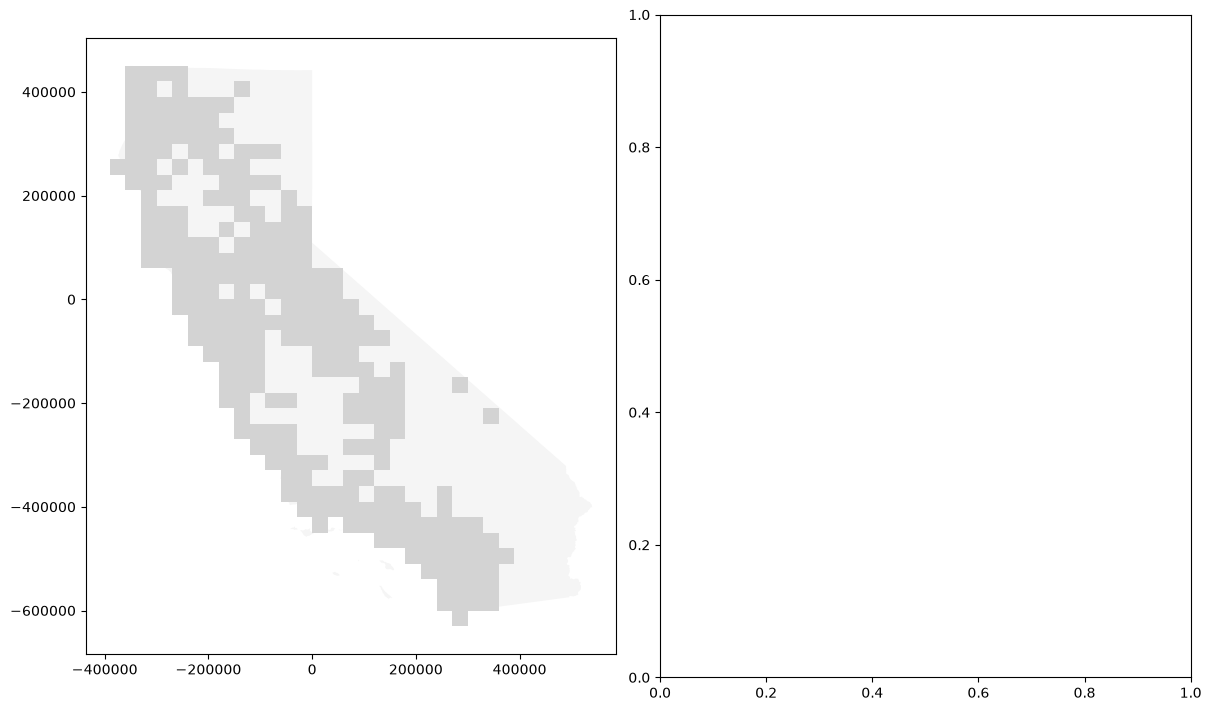

In [59]:
# Assign PCA-based colors, following Lab12.
# Make the linked California grid map and community PCA scatterplot.
# Add the three predictor arrows and a readable legend.
# Save the synthesis figure in OUTPUT.

fig, axes = plt.subplots(1, 2, figsize=(12, 7), layout="constrained")

# A. Show where the observed community trait combinations occur.
california.plot(ax=axes[0], color="whitesmoke")
sites.plot(ax=axes[0], color="lightgray")
map_sites.plot(ax=axes[0], color=community_colors)
axes[0].set_title("A. Community trait combinations")
axes[0].set_axis_off()

# B. Use PCA space as the color key and add latitude, climate, and habitat directions.
ax = axes[1]
ax.scatter(community_scores["PC1"], community_scores["PC2"], c=community_colors)
for predictor, color in zip(FOCUS, ["black", "darkorange", "royalblue"]):
    # Scale both correlations equally so the arrows are easy to see.
    x = 2 * sites[predictor].corr(community_scores["PC1"])
    y = 2 * sites[predictor].corr(community_scores["PC2"])
    label = PREDICTORS[predictor]
    if predictor in CLIMATE_COLUMNS:
        label = "BIO" + predictor.split("_")[1]
    ax.arrow(0, 0, x, y, head_width=0.1, length_includes_head=True,
             color=color, label=label)
    print(label, PREDICTORS[predictor])
ax.legend()
ax.set(title="B. Trait PCA and predictor directions",
       xlabel=f"PC1 ({community_pca.explained_variance_ratio_[0]:.0%})",
       ylabel=f"PC2 ({community_pca.explained_variance_ratio_[1]:.0%})")

figure_path = OUTPUT / "community_trait_environment_map.png"
fig.savefig(figure_path, dpi=200)
plt.show()

,PC1,PC2
MaxBody,-0.237402,0.658078
MinAgeMat,-0.506141,-0.129573
MaxClutch,0.579711,0.181433
MinSizeMat,-0.156041,0.699870
MinClutch,0.571881,0.165553


bio_7     0.188495
bio_4     0.183454
bio_3     0.147214
bio_5     0.143421
bio_13    0.115724
Name: mean_r_squared, dtype: float64

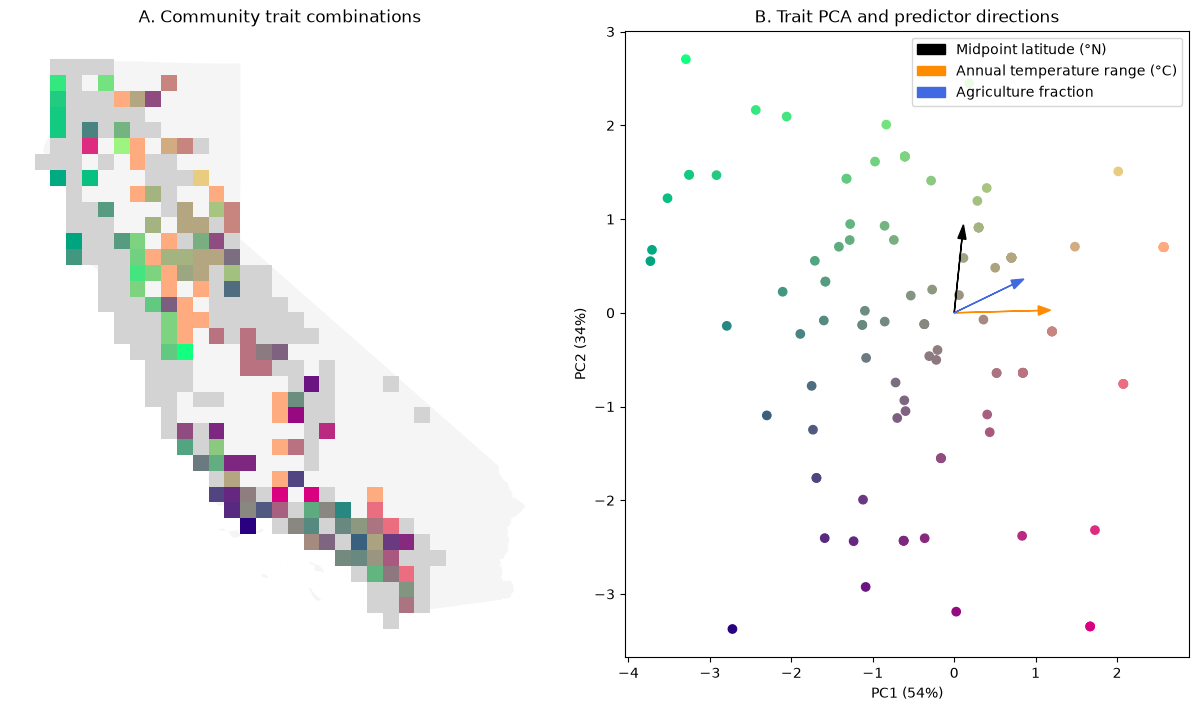

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Build the five community mean traits for the retained functional sites.
community_traits = pd.DataFrame(index=functional_sites.index)
for trait in TRAIT_COLUMNS:
    community_traits[trait] = trait_maps[trait]["trait_mean"]

# Keep cells with positive, finite means for all five traits before taking log10.
community_traits = community_traits.replace([np.inf, -np.inf], np.nan)
community_traits = np.log10(community_traits.where(community_traits > 0).dropna())

# Standardize the log traits and run the community PCA.
scaled_traits = StandardScaler().fit_transform(community_traits)
community_pca = PCA(n_components=2)
scores = community_pca.fit_transform(scaled_traits)

community_scores = pd.DataFrame(
    scores, index=community_traits.index, columns=["PC1", "PC2"]
)
community_loadings = pd.DataFrame(
    community_pca.components_.T, index=community_traits.columns, columns=["PC1", "PC2"]
)
display(community_loadings)

community_loadings.to_csv(OUTPUT / "community loadings pca.csv")

# Match the map cells and predictors to the PCA rows in the same order.
map_sites = functional_sites.loc[community_scores.index].copy()
map_sites[["PC1", "PC2"]] = community_scores

# Rank predictors by their mean squared correlation with all five log traits.
predictor_strength = {}
for predictor in PREDICTORS:
    correlations = community_traits.corrwith(map_sites[predictor])
    predictor_strength[predictor] = correlations.pow(2).mean(skipna=False)

predictor_ranking = pd.Series(predictor_strength, name="mean_r_squared")
predictor_ranking = predictor_ranking.sort_values(ascending=False)

best_climate = predictor_ranking.loc[list(CLIMATE_COLUMNS)].idxmax()
best_habitat = predictor_ranking.loc[list(HABITAT_COLUMNS)].idxmax()
FOCUS = ["latitude", best_climate, best_habitat]
display(predictor_ranking.head())

# Use PC1 for red, PC2 for green, and a constant blue value.
color_scores = MinMaxScaler().fit_transform(community_scores)
rgb = np.column_stack([color_scores, np.full(len(community_scores), 0.5)])
map_sites["pca_color"] = [to_hex(row) for row in np.clip(rgb, 0, 1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 7), layout="constrained")

# A. Map community trait combinations.
california.plot(ax=axes[0], color="whitesmoke")
sites.plot(ax=axes[0], color="lightgray")
map_sites.plot(ax=axes[0], color=map_sites["pca_color"].tolist())
axes[0].set_title("A. Community trait combinations")
axes[0].set_axis_off()

# B. Plot the same cells and colors in PCA space.
ax = axes[1]
ax.scatter(map_sites["PC1"], map_sites["PC2"], c=map_sites["pca_color"].tolist())

for predictor, color in zip(FOCUS, ["black", "darkorange", "royalblue"]):
    x = 2 * map_sites[predictor].corr(map_sites["PC1"])
    y = 2 * map_sites[predictor].corr(map_sites["PC2"])
    ax.arrow(
        0, 0, x, y,
        head_width=0.1,
        length_includes_head=True,
        color=color,
        label=PREDICTORS[predictor],
    )

ax.legend()
ax.set(
    title="B. Trait PCA and predictor directions",
    xlabel=f"PC1 ({community_pca.explained_variance_ratio_[0]:.0%})",
    ylabel=f"PC2 ({community_pca.explained_variance_ratio_[1]:.0%})",
)

OUTPUT.mkdir(parents=True, exist_ok=True)
figure_path = OUTPUT / "community_trait_environment_map.png"
fig.savefig(figure_path, dpi=200)
plt.show()

**Interpretation 8:** What trait combinations occur in different parts of
California? How do the predictor arrows help interpret them? How much variation
is represented by the two axes? Compare this map with richness and FDis.

Contrast one California finding with Maine. The PCAs and color scales are fitted
separately, so matching colors between states do not imply matching traits.
Discuss the loadings and biological trait values rather than comparing colors
or PC signs directly. Habitat classifications also differ between states.

*Your answer:* I see generally three trait combinations that are occuring on the northwest, the central valley, and the southeast of the state. These locations can be explained by the predictor arrows which shows gradients in temperature and agriculture intensity. 88% of the varience is explained by the two axes. Here, there is more dimensions for communities to segregate, whereas this is not possible to see with richness or FDi alone. In that sense, the central valley tends to be different in these variables but it is harder to distinguis differenes between the north and south of the state. 
Trait ordination in Maine is more driven by cold extremes, which do not drive community distribution and composition in California. California is more driven by extreme warm and arid conditions as well as widespread agriculture. Maine does not have as much agriculture, and the developed fraction is more influential in determining the trait space ordination. 

## 8. Save results and synthesize

Save the following in `OUTPUT`: the retained site summaries including coverage,
FDis and SES; the species and community PCA scores and loadings; the predictor
ranking; the observed-FDis Pearson correlation table; and the synthesis figure.
Use CSVs and a GeoPackage with descriptive names.

Write a **400–600 word synthesis** addressing the main question. Use numerical
examples and at least three figures to explain:

- Geographic, climate, and habitat patterns in typical traits and trait spread.
- How richness, observed FDis, and null-model SES answer different questions.
- Which environmental predictors are associated with observed trait dispersion.
- What the community PCA map adds and what the displayed two axes omit.
- How your initial hypothesis compares with the exploratory results.
- How missing traits, sampling, shared species, habitat fractions, and the
  California regional pool limit the conclusions.

Do not describe observation counts as abundance or correlations as causal effects.
Propose one additional biological dataset or survey that would test your explanation.

*Your synthesis:*
For this exploration of functional diversity in California, I hypothesized that the highest diversity would be in ecotones. This was not explicitly analyzed, and I do not know the state well enough to assess exactly where they are. I can assume, however, that they occur to some extent in the north and south of the state, where climatic conditions change from Mediterranean to temperate or arid desert, respectively. Also, ecotones generally occur along the edges of mountain ranges, where communities shift from lowland-dwelling species to those adapted to higher elevations. I would expect some overlap in these areas, where species with different traits may occur within the same grid cell.

In sum, there seemed to be a reflection of these areas in the different analyses. The central valley imposed a strong forcing, although it is hard to disentangle the effects of agriculture, elevation, and climate. This area generally had lower richness but higher functional dispersion, meaning that even though fewer species were present, their traits were more spread out. The higher dispersion could partly be an effect of how much easier it is to sample these areas than the mountain regions.

Latitude, mean annual temperature, and agricultural fraction stood out as predictors of trait distribution and community functional diversity. This again agrees with the gradients I illustrate above and with the effect of latitude, which varies along with changes in climate zones. The two dimensions of the PCA, however, may hide some of the complexity of community trait diversity. Communities with novel combinations of traits may appear close together in these two dimensions, even if they differ along another dimension or respond to different drivers locally. This plot is better than richness or FDis alone for evaluating community relationships across space because I can also see which areas have similar combinations of traits.

I think that my original hypothesis is generally supported, although the central valley imposed a different effect that I did not consider initially, as I had not realized how agricultural that sector is. Although measuring traits is neither newer nor necessarily more complex than identifying species, traits are less commonly surveyed. This may have hampered the results, but I get the sense that this is a growing database. Again, due to the complex topography, certain areas may remain less sampled, possibly biasing richness and diversity results. Habitat fractions may also change over time. A cell that is agricultural today may still contain species associated with its previous habitat, and these legacy effects would be difficult to assess from the current habitat fractions alone.


In [63]:
# Save your site summaries, PCA tables, predictor ranking, FDis correlations,
# and synthesis figure.



### Sources

- [California preprocessing and missing-trait notes](../data/Lab12/CA_preprocessing.md).
- [California occurrence, boundary, and climate provenance](../data/CA_data_README.md).
- [GBIF download DOI](https://doi.org/10.15468/dl.wbj54a).
- [AmphiTraits](https://doi.org/10.5066/P135WFOE), supplied `AmphiTraits_Final.csv`.
- Supplied GAP/LANDFIRE National Terrestrial Ecosystems 2011 habitat raster and legend.
- [Lab12: Spatial trait variation](../labs/Lab12-SpatialTraitVariation.ipynb).
- [Functional dispersion: Laliberté & Legendre (2010)](https://doi.org/10.1890/08-2244.1).